In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
DATA = "/content/tse-project/DATA"
SPLITS = {
    "dev-clean":40,
    "test-clean":40,
    "train-clean-100": 251,
    "train-clean-360": 921
}
DEMAND = ["DKITCHEN", "DLIVING", "DWASHING", "NFIELD", "NPARK", "NRIVER",
          "OHALLWAY", "OMEETING", "OOFFICE", "PCAFETER", "PRESTO", "PSTATION",
          "SPSQUARE", "STRAFFIC", "TBUS", "TCAR", "TMETRO"]

os.environ["DATA"] = DATA
os.environ["SPLITS"] = " ".join(f"{k}:{v}" for k, v in SPLITS.items())
os.environ["DEMAND"] = " ".join(DEMAND)

In [ ]:
%%bash
apt-get -qq install -y aria2 > /dev/null
mkdir -p $DATA/dl $DATA/DEMAND $DATA/LibriSpeech
df -h /content | tail -1

%%bash
cd $DATA/dl
for item in $SPLITS; do
  s=${item%%:*}; n=${item##*:}
  have=$(ls $DATA/LibriSpeech/$s 2>/dev/null | wc -l)
  if [ "$have" -eq "$n" ]; then echo "$s: already present"; continue; fi

  echo "Downloading $s ..."
  aria2c -x 16 -s 16 -k 4M -c -q --max-tries=0 --retry-wait=5 \
    https://www.openslr.org/resources/12/$s.tar.gz \
    && tar -xzf $s.tar.gz -C $DATA && rm $s.tar.gz

  echo "$s: $(ls $DATA/LibriSpeech/$s | wc -l) speakers (expected $n)"
done
df -h /content | tail -1

overlay         236G   43G  194G  19% /
dev-clean: 40 speakers (expected 40)
test-clean: 40 speakers (expected 40)
train-clean-100: 251 speakers (expected 251)
train-clean-360: 921 speakers (expected 921)
overlay         236G   72G  164G  31% /


bash: line 5: fg: no job control


In [ ]:
from huggingface_hub import snapshot_download
import glob, os, zipfile

DATA = os.environ.get("DATA", "/content/data")   # change if your notebook uses another path
ZIP_DIR = f"{DATA}/dl"
OUT_DIR = f"{DATA}/DEMAND"
os.makedirs(ZIP_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Download the zips that exist in the repo (the 14 available)
snapshot_download(
    "Sostika/demand",
    repo_type="dataset",
    local_dir=ZIP_DIR,
    allow_patterns=["*_16k.zip"],
)

# Extract each one, skipping environments that already have 16 wavs
for z in sorted(glob.glob(f"{ZIP_DIR}/*_16k.zip")):
    name = os.path.basename(z).replace("_16k.zip", "")
    target = f"{OUT_DIR}/{name}"
    n_wav = sum(f.endswith(".wav") for _, _, fs in os.walk(target) for f in fs)
    if n_wav >= 16:
        print(f"{name}: already present")
        continue
    with zipfile.ZipFile(z) as zf:
        zf.extractall(target)
    os.remove(z)   # free disk space after extracting
    print(f"{name}: extracted")

# Check
for d in sorted(os.listdir(OUT_DIR)):
    n = sum(f.endswith(".wav") for _, _, fs in os.walk(f"{OUT_DIR}/{d}") for f in fs)
    print(f"{d}: {n} wav files")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

DKITCHEN: extracted
DLIVING: extracted
DWASHING: extracted
NFIELD: extracted
NPARK: extracted
NRIVER: extracted
OHALLWAY: extracted
OMEETING: extracted
OOFFICE: extracted
PRESTO: extracted
PSTATION: extracted
SPSQUARE: extracted
STRAFFIC: extracted
TBUS: extracted
TCAR: extracted
TMETRO: extracted
DKITCHEN: 16 wav files
DLIVING: 16 wav files
DWASHING: 16 wav files
NFIELD: 16 wav files
NPARK: 16 wav files
NRIVER: 16 wav files
OHALLWAY: 16 wav files
OMEETING: 16 wav files
OOFFICE: 16 wav files
PRESTO: 16 wav files
PSTATION: 16 wav files
SPSQUARE: 16 wav files
STRAFFIC: 16 wav files
TBUS: 16 wav files
TCAR: 16 wav files
TMETRO: 16 wav files


In [ ]:
!pip -q install speechbrain pystoi pyyaml
!pip -q install pesq 2>&1 | tail -1

import sys, gc, numpy as np, pandas as pd, torch, yaml
import torch.utils.checkpoint as ckp

DATA = "/content/tse-project/DATA"
PROJ = "/content/drive/MyDrive/tse-project"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0))

sys.path.insert(0, PROJ)
import tselib as T

# config + manifests + cached embedding banks (all read from disk, nothing is rebuilt)
cfg = T.load_cfg(f"{PROJ}/config.yaml")
D = T.proj_dirs(cfg)
lib   = pd.read_csv(f"{D['manifests']}/librispeech.csv")
noise = pd.read_csv(f"{D['manifests']}/noise.csv")
banks = {r: T.load_bank(f"{D['embeddings']}/{r}") for r in ["train", "val", "test"]}

SEG = {"train": cfg["audio"]["train_seconds"], "val": cfg["audio"]["eval_seconds"], "test": cfg["audio"]["eval_seconds"]}
samplers = {r: T.SceneSampler(T.role_df(lib, cfg, r), noise, banks[r][0], cfg, r, SEG[r]) for r in SEG}
man_val  = pd.read_csv(f"{D['manifests']}/val_mix.csv")
man_test = pd.read_csv(f"{D['manifests']}/test_mix.csv")

# big model config
cfg_big = T._merge(cfg, {
    "model": {"N": 128, "hidden": 256, "layers": 8},
    "train": {"epochs": 100, "steps_per_epoch": 1000, "batch_size": 8,
              "lr": 5e-4, "warmup_steps": 2000, "num_workers": 2},
})
T.save_cfg(cfg_big, f"{PROJ}/config_big.yaml")
TAG = "tse_bsrnn_big"
tcb = cfg_big["train"]

# memory fix: gradient checkpointing on every dual-path layer
if not hasattr(T.DualPathLayer, "_orig_forward"):
    T.DualPathLayer._orig_forward = T.DualPathLayer.forward
    def _ckpt_forward(self, x, spk):
        if self.training and torch.is_grad_enabled():
            return ckp.checkpoint(T.DualPathLayer._orig_forward, self, x, spk, use_reentrant=False)
        return T.DualPathLayer._orig_forward(self, x, spk)
    T.DualPathLayer.forward = _ckpt_forward

gc.collect(); torch.cuda.empty_cache()
print(f"{T.count_params(T.TSEBSRNN(cfg_big['model']))/1e6:.1f} M parameters | GPU in use: {torch.cuda.memory_allocated()/2**30:.2f} GiB")

2.11.0+cu130 cuda NVIDIA L4
16.8 M parameters | GPU in use: 0.00 GiB


In [ ]:
import time
model = T.TSEBSRNN(cfg_big["model"]).to(device).train()
ds = T.TSEDataset(samplers["train"], banks["train"][1], 12 * tcb["batch_size"], DATA)
dl = torch.utils.data.DataLoader(ds, batch_size=tcb["batch_size"], num_workers=tcb["num_workers"], drop_last=True)
batches = [b for b in dl]
opt = torch.optim.AdamW(model.parameters(), 1e-4)
scaler = torch.amp.GradScaler("cuda")
torch.cuda.reset_peak_memory_stats(); times = []
for mix, tgt, emb, _ in batches[:10]:
    mix, tgt, emb = mix.to(device), tgt.to(device), emb.to(device)
    torch.cuda.synchronize(); t0 = time.time()
    with torch.autocast("cuda", dtype=torch.float16):
        est = model(mix, emb)
    loss, _ = T.tse_loss(est, tgt, tcb["w_sisdr"], tcb["w_mrstft"])
    opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    torch.cuda.synchronize(); times.append(time.time() - t0)
print(f"{np.mean(times[3:]):.2f} s/step | peak GPU memory {torch.cuda.max_memory_allocated()/2**30:.1f} GiB")
del model, opt, batches, est, loss; gc.collect(); torch.cuda.empty_cache()

0.99 s/step | peak GPU memory 3.2 GiB


In [ ]:
model = T.TSEBSRNN(cfg_big["model"])
train_ds = T.TSEDataset(samplers["train"], banks["train"][1], tcb["batch_size"] * tcb["steps_per_epoch"], DATA)
val_ds   = T.FixedDataset(man_val, banks["val"][1], DATA, cfg_big["audio"]["eval_seconds"], cfg_big["mix"]["peak_limit"])

log = T.train(cfg_big, model, train_ds, val_ds, D["checkpoints"], D["logs"], device, tag=TAG)

Resumed from epoch 33 (best val SI-SDRi so far: 8.12 dB)


epoch 34/100:   0%|          | 0/1000 [00:00<?, ?it/s]

epoch 34 | loss -4.872 | train SI-SDR 10.91 | val SI-SDR 10.34 | val SI-SDRi 8.53 | 17.2 min


epoch 35/100:   0%|          | 0/1000 [00:00<?, ?it/s]

epoch 35 | loss -5.109 | train SI-SDR 11.09 | val SI-SDR 10.59 | val SI-SDRi 8.63 | 17.4 min


epoch 36/100:   0%|          | 0/1000 [00:00<?, ?it/s]

... (125 outputs left out)

epoch 99/100:   0%|          | 0/1000 [00:00<?, ?it/s]

epoch 99 | loss -9.754 | train SI-SDR 15.10 | val SI-SDR 14.12 | val SI-SDRi 11.73 | 17.5 min


epoch 100/100:   0%|          | 0/1000 [00:00<?, ?it/s]

epoch 100 | loss -9.844 | train SI-SDR 15.19 | val SI-SDR 14.10 | val SI-SDRi 11.69 | 17.4 min


In [ ]:
import glob, gc, os
from IPython.display import Audio, display

gc.collect(); torch.cuda.empty_cache()

test_ds = T.FixedDataset(man_test, banks["test"][1], DATA,
                         cfg_big["audio"]["eval_seconds"], cfg_big["mix"]["peak_limit"])
print("test mixtures:", len(test_ds))

# find checkpoint (prefers *best*, otherwise newest)
cands = sorted(glob.glob(f"{D['checkpoints']}/*{TAG}*"), key=os.path.getmtime)
print("checkpoints found:"); [print("  ", os.path.basename(c)) for c in cands]
best = [c for c in cands if "best" in os.path.basename(c).lower()]
CKPT = (best or cands)[-1]          # <- override manually if you want a specific one
print("using:", CKPT)

ck = torch.load(CKPT, map_location="cpu", weights_only=False)
if isinstance(ck, dict):
    state = next((ck[k] for k in ("model", "model_state", "model_state_dict", "state_dict", "net") if k in ck), ck)
    print("checkpoint keys:", list(ck.keys())[:10])
else:
    state = ck
state = {k.replace("module.", "", 1): v for k, v in state.items()}

# fresh model object, so the training-time `model` variable is not touched
model_eval = T.TSEBSRNN(cfg_big["model"])
print(model_eval.load_state_dict(state, strict=False))
model = model_eval.to(device).eval()

test mixtures: 1200
checkpoints found:
   tse_bsrnn_big_best.pt
   tse_bsrnn_big_last.pt
using: /content/drive/MyDrive/tse-project/checkpoints/tse_bsrnn_big_best.pt
checkpoint keys: ['model', 'cfg', 'epoch', 'val_si_sdri']
<All keys matched successfully>


=== example 323 | SI-SDR in -3.50 dB -> out 12.27 dB (improvement +15.77 dB)
1) Mixture (target + interferer + noise)


2) Model output (extracted target)


3) Clean target (reference)


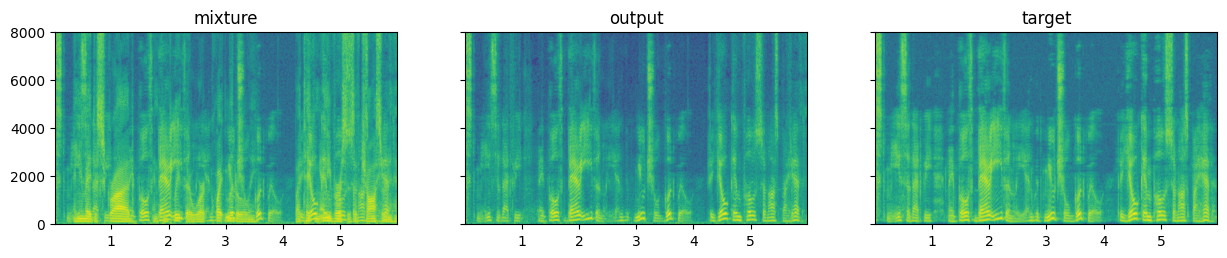

=== example 761 | SI-SDR in 3.80 dB -> out 21.57 dB (improvement +17.77 dB)
1) Mixture (target + interferer + noise)


2) Model output (extracted target)


3) Clean target (reference)


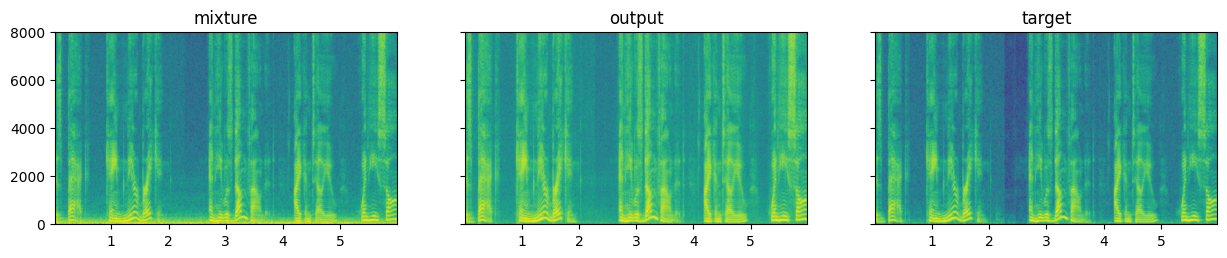

=== example 611 | SI-SDR in 2.52 dB -> out 17.88 dB (improvement +15.36 dB)
1) Mixture (target + interferer + noise)


2) Model output (extracted target)


3) Clean target (reference)


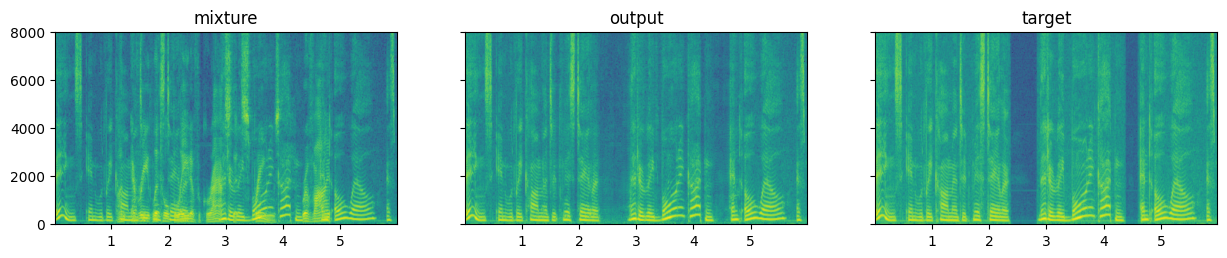

=== example 369 | SI-SDR in -0.77 dB -> out 20.67 dB (improvement +21.44 dB)
1) Mixture (target + interferer + noise)


2) Model output (extracted target)


3) Clean target (reference)


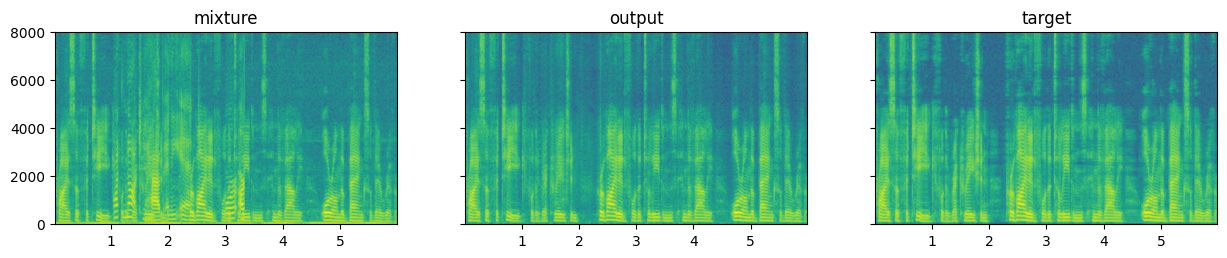

=== example 49 | SI-SDR in 1.60 dB -> out 12.88 dB (improvement +11.27 dB)
1) Mixture (target + interferer + noise)


2) Model output (extracted target)


3) Clean target (reference)


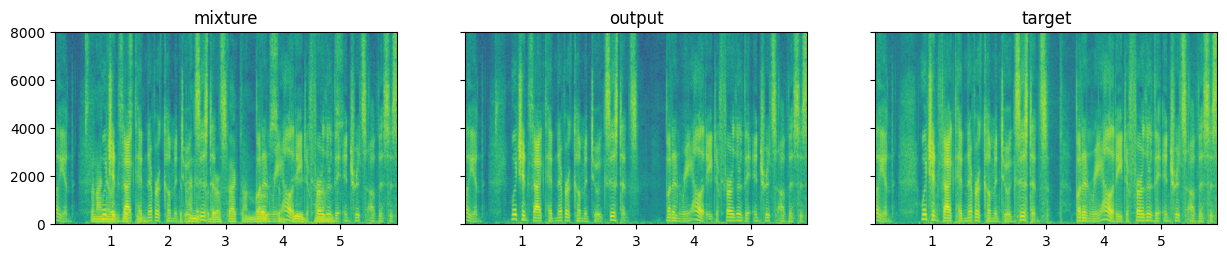

=== example 1016 | SI-SDR in -0.66 dB -> out 11.38 dB (improvement +12.04 dB)
1) Mixture (target + interferer + noise)


2) Model output (extracted target)


3) Clean target (reference)


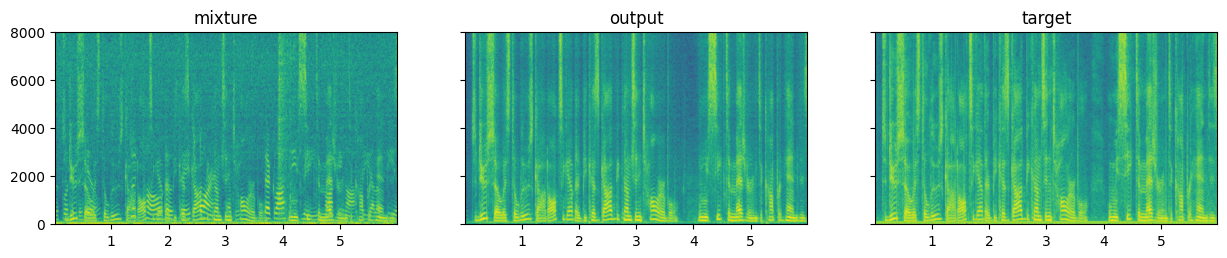

In [ ]:
import matplotlib.pyplot as plt, soundfile as sf
SR = 16000

def si_sdr(est, ref, eps=1e-8):
    est, ref = est - est.mean(), ref - ref.mean()
    proj = (est @ ref) / (ref @ ref + eps) * ref
    return 10 * np.log10((proj @ proj) / (((est - proj) @ (est - proj)) + eps) + eps)

@torch.no_grad()
def run(i):
    mix, tgt, emb, *_ = test_ds[i]
    mix, tgt, emb = [torch.as_tensor(x) for x in (mix, tgt, emb)]
    m = mix.reshape(1, -1).to(device); e = emb.reshape(1, -1).to(device) if emb.ndim < 2 else emb.unsqueeze(0).to(device) if emb.ndim == 2 and emb.shape[0] != 1 else emb.to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        est = model(m, e)
    return mix.reshape(-1).numpy(), tgt.reshape(-1).numpy(), est.float().reshape(-1).cpu().numpy()

os.makedirs(f"{PROJ}/samples", exist_ok=True)
rng = np.random.default_rng(0)
for i in rng.choice(len(test_ds), 6, replace=False):
    mix, tgt, est = run(int(i))
    n = min(len(mix), len(tgt), len(est)); mix, tgt, est = mix[:n], tgt[:n], est[:n]
    s_in, s_out = si_sdr(mix, tgt), si_sdr(est, tgt)
    print(f"=== example {i} | SI-SDR in {s_in:.2f} dB -> out {s_out:.2f} dB (improvement {s_out - s_in:+.2f} dB)")
    for name, x in [("1) Mixture (target + interferer + noise)", mix), ("2) Model output (extracted target)", est), ("3) Clean target (reference)", tgt)]:
        print(name); display(Audio(x, rate=SR))
    for name, x in [("mix", mix), ("est", est), ("tgt", tgt)]:
        sf.write(f"{PROJ}/samples/ex{i}_{name}.wav", x, SR)
    fig, ax = plt.subplots(1, 3, figsize=(15, 2.5), sharey=True)
    for a, (t, x) in zip(ax, [("mixture", mix), ("output", est), ("target", tgt)]):
        a.specgram(x, Fs=SR, NFFT=512, noverlap=384); a.set_title(t)
    plt.show()

In [ ]:
import pandas as pd
df = pd.read_csv(f"{PROJ}/test_metrics.csv")
print(len(df), "rows loaded"); df.head()

1200 rows loaded


,idx,sisdr_in,sisdr_out,stoi_in,stoi_out,pesq_out,sisdri
0,0,-2.299697,0.192527,0.716427,0.651111,1.205426,2.492224
1,1,0.237076,14.007681,0.791893,0.967244,3.070347,13.770605
2,2,3.307572,-5.523436,0.877980,0.669264,1.165345,-8.831009
3,3,-0.243938,14.508258,0.792372,0.912867,2.245469,14.752196
4,4,100.235550,43.673280,1.000000,0.999985,4.640667,-56.562270


/tmp/ipykernel_3818/2334494505.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1,1].boxplot([df.sisdr_in, df.sisdr_out], labels=["input", "output"], showmeans=True)


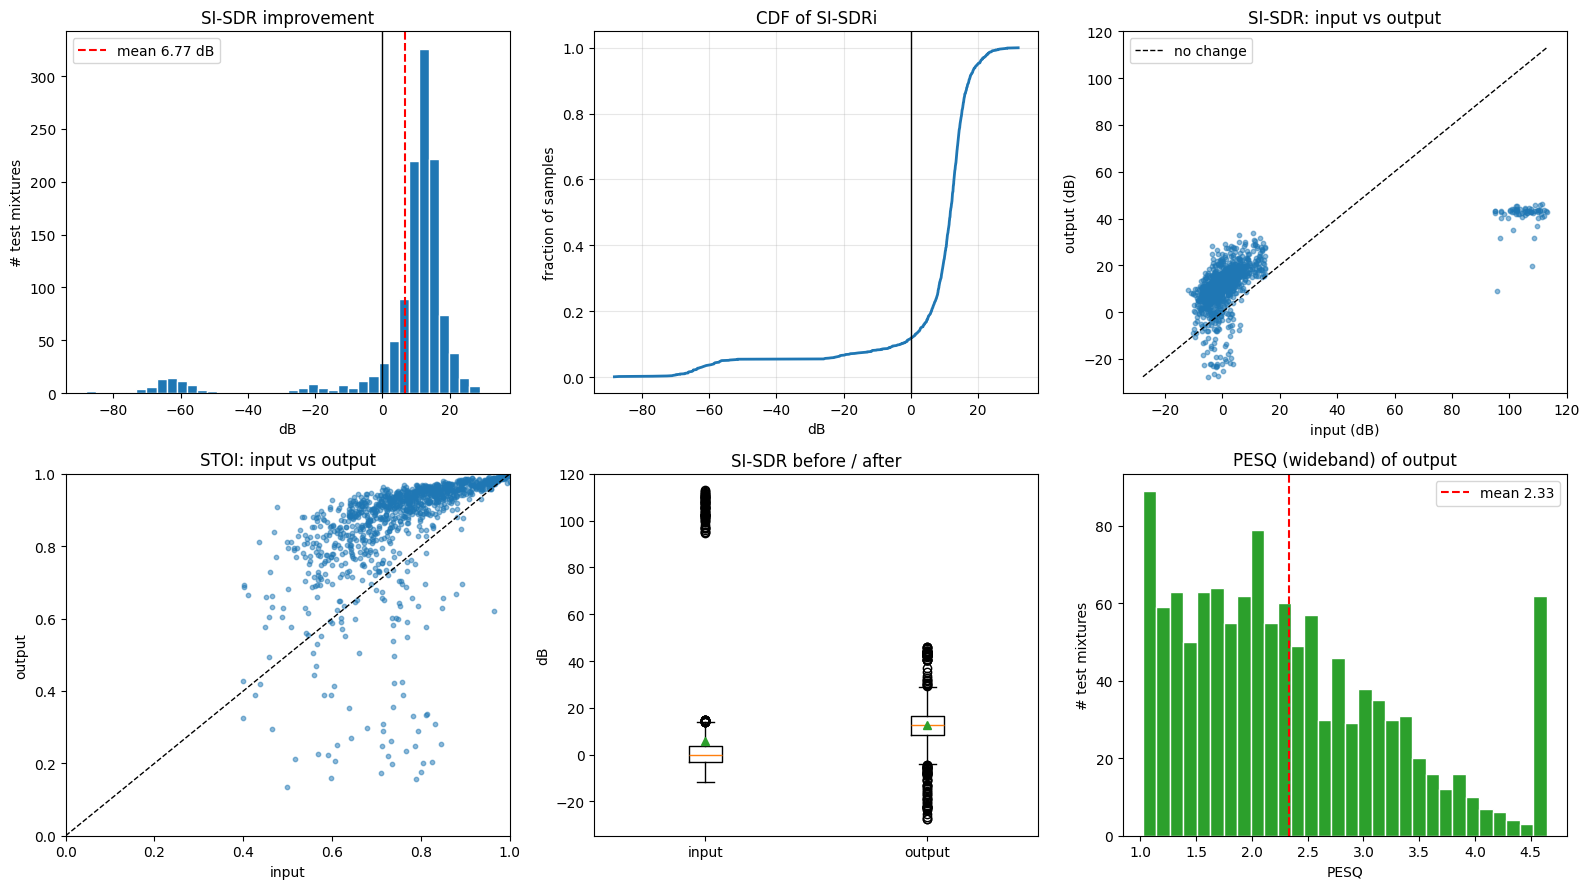

Helped (SI-SDRi > 0): 88.3% of samples
Worst 5 samples by SI-SDRi:
     idx  sisdr_in  sisdr_out  sisdri
568  568    107.84      19.67  -88.17
678  678     95.82       8.97  -86.86
866  866    108.50      31.71  -76.79
184  184    109.50      36.94  -72.56
311  311    112.02      41.02  -71.01


In [ ]:
import matplotlib.pyplot as plt, numpy as np

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

# 1) SI-SDRi histogram
ax[0,0].hist(df.sisdri, bins=40, color="tab:blue", edgecolor="white")
ax[0,0].axvline(df.sisdri.mean(), color="red", ls="--", label=f"mean {df.sisdri.mean():.2f} dB")
ax[0,0].axvline(0, color="k", lw=1)
ax[0,0].set(title="SI-SDR improvement", xlabel="dB", ylabel="# test mixtures"); ax[0,0].legend()

# 2) CDF of SI-SDRi (read: "x% of samples improve by less than y dB")
s = np.sort(df.sisdri); ax[0,1].plot(s, np.arange(1, len(s)+1)/len(s), lw=2)
ax[0,1].axvline(0, color="k", lw=1); ax[0,1].grid(alpha=.3)
ax[0,1].set(title="CDF of SI-SDRi", xlabel="dB", ylabel="fraction of samples")

# 3) SI-SDR in vs out (points above the diagonal = model helped)
lo, hi = min(df.sisdr_in.min(), df.sisdr_out.min()), max(df.sisdr_in.max(), df.sisdr_out.max())
ax[0,2].scatter(df.sisdr_in, df.sisdr_out, s=10, alpha=.5)
ax[0,2].plot([lo, hi], [lo, hi], "k--", lw=1, label="no change"); ax[0,2].legend()
ax[0,2].set(title="SI-SDR: input vs output", xlabel="input (dB)", ylabel="output (dB)")

# 4) STOI in vs out
ax[1,0].scatter(df.stoi_in, df.stoi_out, s=10, alpha=.5)
ax[1,0].plot([0, 1], [0, 1], "k--", lw=1)
ax[1,0].set(title="STOI: input vs output", xlabel="input", ylabel="output", xlim=(0,1), ylim=(0,1))

# 5) Box plots: before vs after
ax[1,1].boxplot([df.sisdr_in, df.sisdr_out], labels=["input", "output"], showmeans=True)
ax[1,1].set(title="SI-SDR before / after", ylabel="dB")

# 6) PESQ distribution
ax[1,2].hist(df.pesq_out.dropna(), bins=30, color="tab:green", edgecolor="white")
ax[1,2].axvline(df.pesq_out.mean(), color="red", ls="--", label=f"mean {df.pesq_out.mean():.2f}")
ax[1,2].set(title="PESQ (wideband) of output", xlabel="PESQ", ylabel="# test mixtures"); ax[1,2].legend()

plt.tight_layout()
plt.savefig(f"{PROJ}/test_metrics_plots.png", dpi=150)
plt.show()

print(f"Helped (SI-SDRi > 0): {(df.sisdri > 0).mean()*100:.1f}% of samples")
print(f"Worst 5 samples by SI-SDRi:\n{df.nsmallest(5, 'sisdri')[['idx','sisdr_in','sisdr_out','sisdri']].round(2)}")

In [ ]:
print(man_test.columns.tolist())
man_test.head(3)

['id', 'scenario', 'tgt_spk', 'tgt_path', 'tgt_start', 'int_spk', 'int_path', 'int_len', 'int_start', 'int_off', 'sir', 'noise_path', 'noise_start', 'snr', 'level_db', 'enroll_idx', 'enroll_dur']


,id,scenario,tgt_spk,tgt_path,tgt_start,int_spk,int_path,int_len,int_start,int_off,sir,noise_path,noise_start,snr,level_db,enroll_idx,enroll_dur
0,0,speech_noise,3729,LibriSpeech/test-clean/3729/6852/3729-6852-004...,69963,4446.0,LibriSpeech/test-clean/4446/2271/4446-2271-002...,87562.0,4098.0,6181.0,3.759185,DEMAND/DKITCHEN/DKITCHEN/ch14.wav,4400897.0,0.251389,-26.108992,117,3.0
1,1,speech_noise,6930,LibriSpeech/test-clean/6930/81414/6930-81414-0...,51011,1284.0,LibriSpeech/test-clean/1284/1181/1284-1181-001...,68104.0,29828.0,18134.0,3.711518,DEMAND/TBUS/TBUS/ch06.wav,4674796.0,3.014495,-34.075381,181,5.0
2,2,speech,7176,LibriSpeech/test-clean/7176/92135/7176-92135-0...,13650,2830.0,LibriSpeech/test-clean/2830/3980/2830-3980-002...,43747.0,75161.0,8001.0,-0.113798,NaN,NaN,NaN,-28.478501,203,12.0


['epoch', 'train_loss', 'train_si_sdr', 'val_si_sdr', 'val_si_sdri', 'lr', 'skipped', 'minutes']


,epoch,train_loss,train_si_sdr,val_si_sdr,val_si_sdri,lr,skipped,minutes
97,98,-9.864474,15.179761,14.143755,11.725304,0.000011,0,17.457430
98,99,-9.754353,15.096210,14.122912,11.729177,0.000010,0,17.472270
99,100,-9.844299,15.194879,14.100507,11.688693,0.000010,0,17.422033


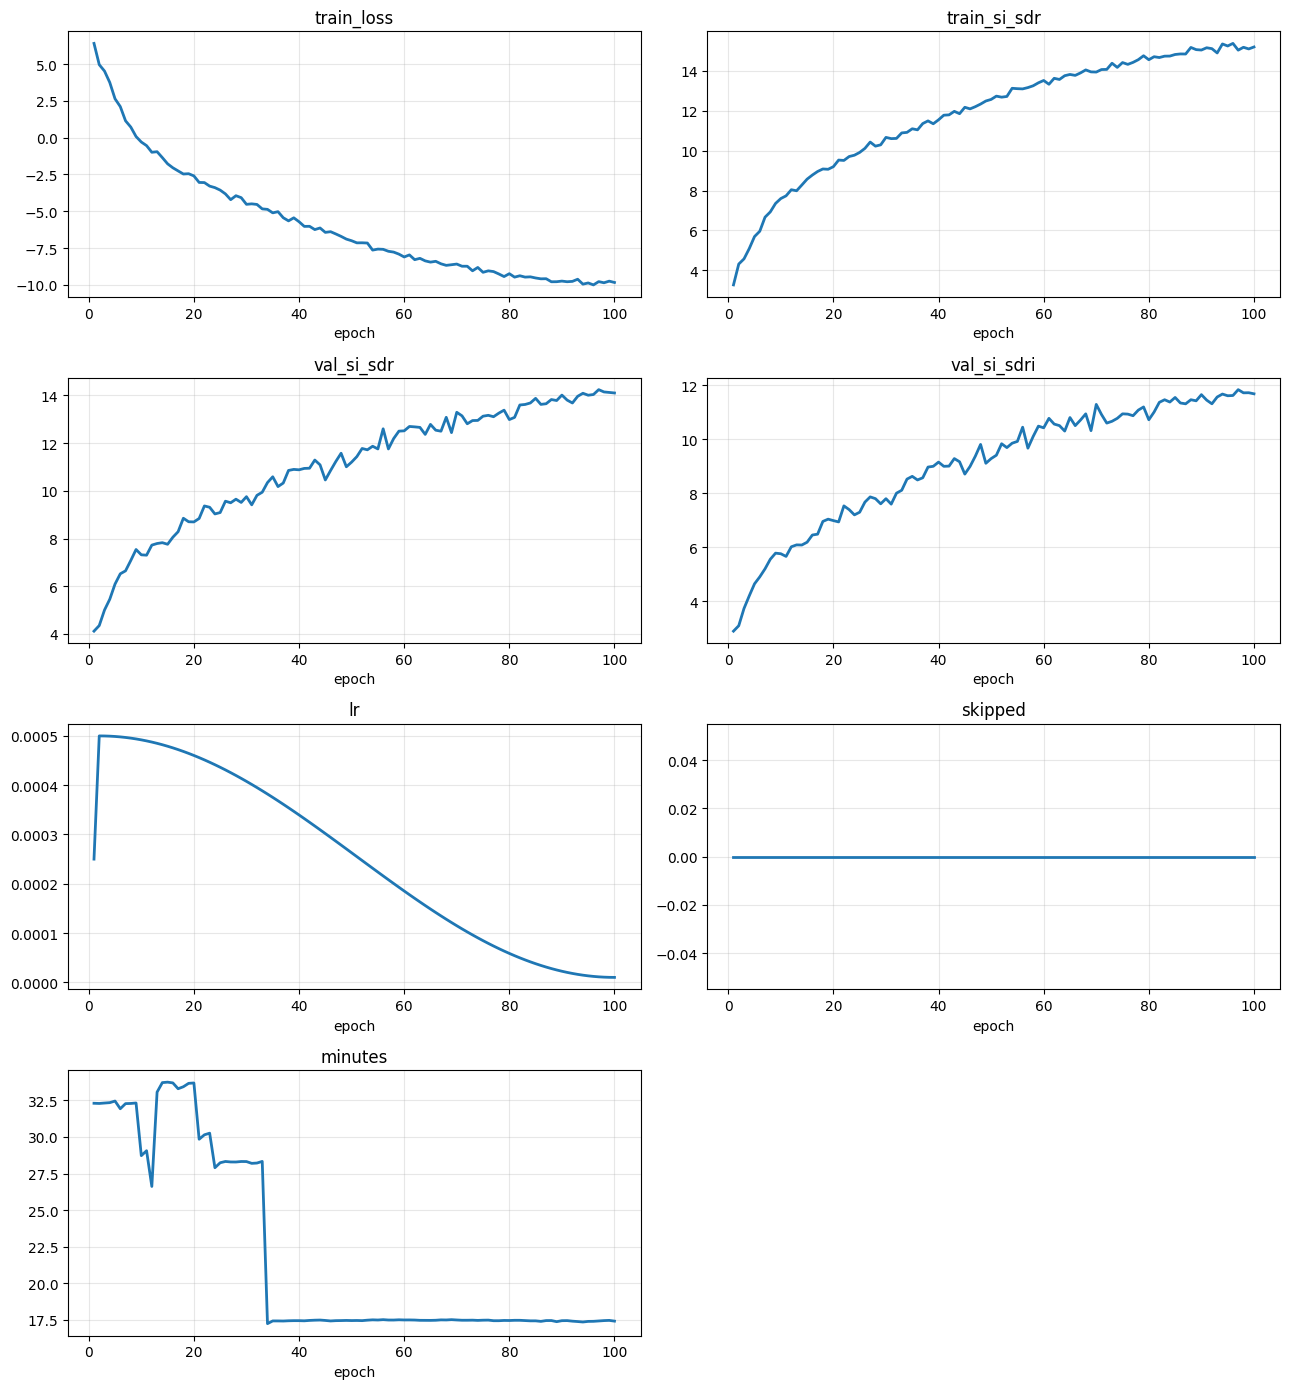

In [ ]:
import pandas as pd
L = pd.DataFrame(log) if not isinstance(log, pd.DataFrame) else log
print(L.columns.tolist()); display(L.tail(3))

num = [c for c in L.columns if pd.api.types.is_numeric_dtype(L[c]) and c.lower() not in ("epoch", "step")]
cols = 2
rows = int(np.ceil(len(num) / cols))
fig, ax = plt.subplots(rows, cols, figsize=(13, 3.5 * rows)); ax = np.atleast_1d(ax).ravel()
x = L["epoch"] if "epoch" in L else L.index
for a, c in zip(ax, num):
    a.plot(x, L[c], lw=2); a.set_title(c); a.set_xlabel("epoch"); a.grid(alpha=.3)
for a in ax[len(num):]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{PROJ}/training_curves.png", dpi=150); plt.show()


=== by scenario ===


,n,sisdri,sisdri_std,stoi_out,pesq
group,,,,,
clean,65,-63.22,6.79,1.00,4.62
noise,290,13.51,6.28,0.95,2.89
speech,294,9.65,8.12,0.88,2.29
speech_noise,551,9.93,7.35,0.83,1.78



=== by sir ===


,n,sisdri,sisdri_std,stoi_out,pesq
group,,,,,
"(-4.997, -3.325]",131,11.98,7.20,0.83,1.81
"(-3.325, -1.663]",152,9.03,9.68,0.80,1.80
"(-1.663, -0.00112]",134,10.57,6.86,0.85,1.91
"(-0.00112, 1.661]",147,10.22,5.63,0.87,1.99
"(1.661, 3.323]",144,8.42,8.03,0.86,2.05
"(3.323, 4.985]",137,9.03,7.12,0.88,2.19



=== by snr ===


,n,sisdri,sisdri_std,stoi_out,pesq
group,,,,,
"(-5.009, -1.668]",155,12.86,7.18,0.80,1.77
"(-1.668, 1.654]",136,13.05,6.53,0.86,2.05
"(1.654, 4.976]",142,11.75,6.50,0.87,2.22
"(4.976, 8.297]",135,10.83,7.55,0.89,2.31
"(8.297, 11.619]",126,9.05,8.49,0.88,2.27
"(11.619, 14.941]",147,9.20,5.93,0.91,2.42



=== by noise_env ===


,n,sisdri,sisdri_std,stoi_out,pesq
group,,,,,
DKITCHEN,57,13.87,5.52,0.92,2.56
DLIVING,61,9.14,5.11,0.85,1.79
DWASHING,33,17.76,7.82,0.92,2.77
NFIELD,44,12.86,7.52,0.88,2.26
NPARK,52,11.14,6.28,0.85,1.90
NRIVER,44,12.01,6.95,0.86,2.08
OHALLWAY,53,13.40,6.60,0.88,2.33
OMEETING,65,8.38,4.46,0.83,1.82
OOFFICE,48,13.22,6.91,0.89,2.35



=== by enroll_dur ===


,n,sisdri,sisdri_std,stoi_out,pesq
group,,,,,
2.0,182,6.80,18.66,0.87,2.31
3.0,231,3.93,21.53,0.86,2.29
5.0,334,7.48,17.20,0.89,2.37
8.0,271,7.38,17.99,0.88,2.36
12.0,182,8.10,15.76,0.89,2.29


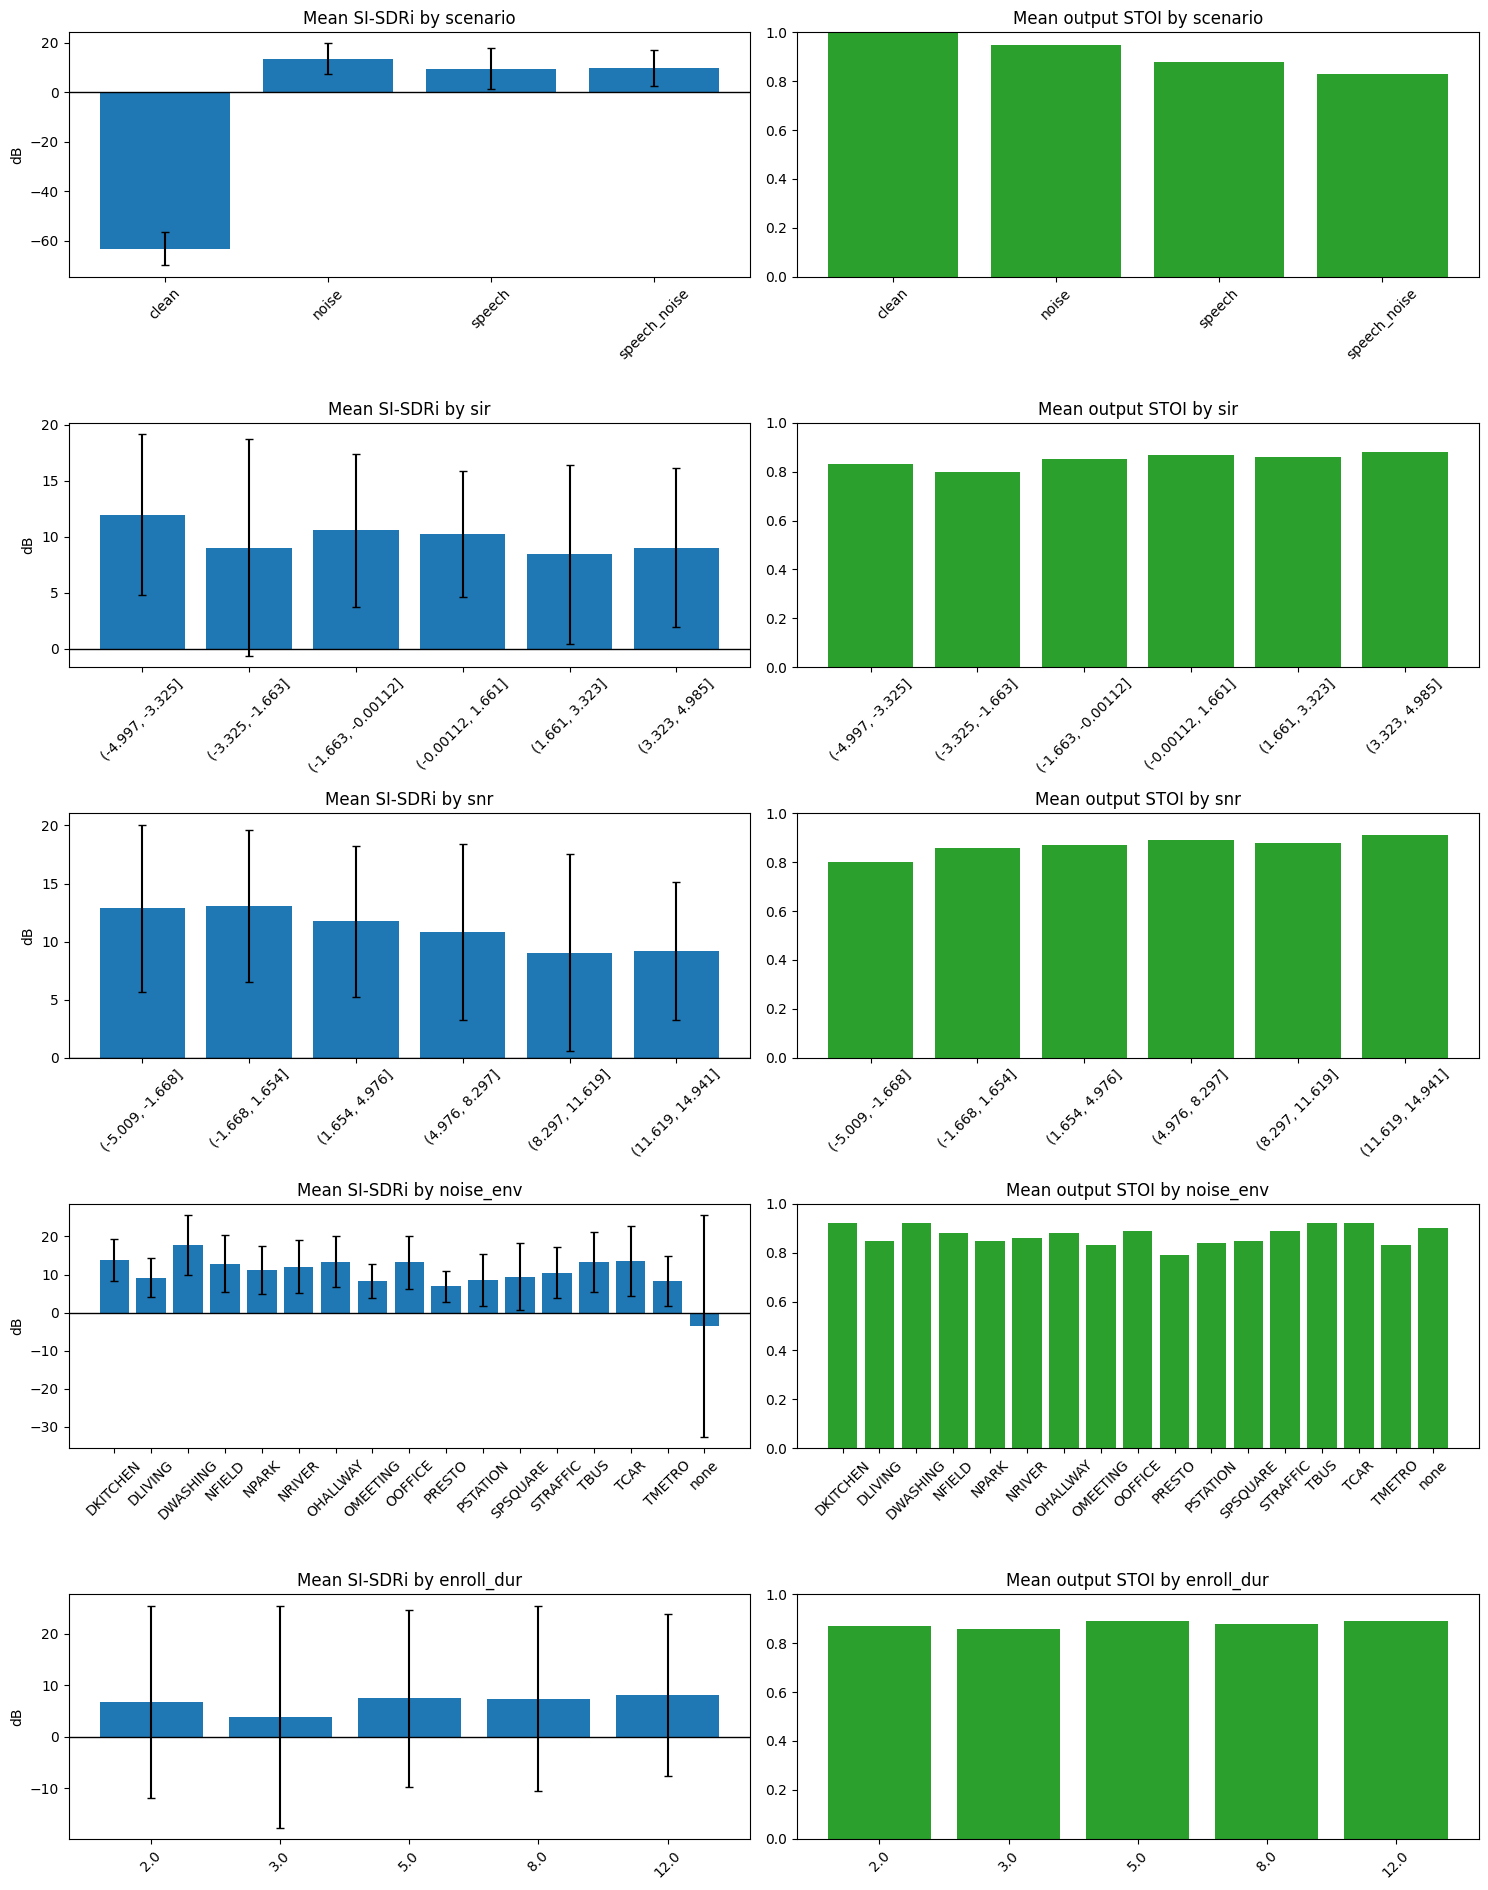


Correlation with SI-SDRi:
sir          -0.11
snr          -0.21
level_db     -0.01
enroll_dur    0.05
sisdr_in     -0.90
dtype: float64


In [ ]:
import matplotlib.pyplot as plt, numpy as np, pandas as pd

# join metrics with scenario info (row i of df == row i of man_test)
d = df.merge(man_test.reset_index().rename(columns={"index": "idx"}), on="idx")
d["noise_env"] = d["noise_path"].str.extract(r"DEMAND/([^/]+)/")[0].fillna("none")

def breakdown(col, bins=None, rot=0):
    x = d.copy()
    if bins:
        x["group"] = pd.cut(x[col], bins=bins)
    else:
        x["group"] = x[col]
    x = x.dropna(subset=["group"])
    g = x.groupby("group", observed=True).agg(
        n=("sisdri", "size"), sisdri=("sisdri", "mean"), sisdri_std=("sisdri", "std"),
        stoi_out=("stoi_out", "mean"), pesq=("pesq_out", "mean")).round(2)
    print(f"\n=== by {col} ==="); display(g)
    return x, g

conds = [("scenario", None), ("sir", 6), ("snr", 6), ("noise_env", None), ("enroll_dur", None)]
fig, ax = plt.subplots(len(conds), 2, figsize=(15, 3.8 * len(conds)))
for row, (col, bins) in zip(ax, conds):
    x, g = breakdown(col, bins)
    labels = [str(i) for i in g.index]
    row[0].bar(labels, g["sisdri"], yerr=g["sisdri_std"], color="tab:blue", capsize=3)
    row[0].axhline(0, color="k", lw=1)
    row[0].set(title=f"Mean SI-SDRi by {col}", ylabel="dB"); row[0].tick_params(axis="x", rotation=45)
    row[1].bar(labels, g["stoi_out"], color="tab:green")
    row[1].set(title=f"Mean output STOI by {col}", ylim=(0, 1)); row[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(f"{PROJ}/test_breakdown_plots.png", dpi=150)
plt.show()

# does harder input (lower SIR) mean worse output? quick correlation check
print("\nCorrelation with SI-SDRi:")
print(d[["sir", "snr", "level_db", "enroll_dur", "sisdr_in"]].corrwith(d["sisdri"]).round(2))

In [ ]:
from tqdm.auto import tqdm
cache = {}
for i in tqdm(range(len(test_ds))):
    mix, tgt, est = run(i)
    n = min(len(mix), len(tgt), len(est))
    cache[i] = (mix[:n], tgt[:n], est[:n])
print("cached", len(cache), "samples")

  0%|          | 0/1200 [00:00<?, ?it/s]

cached 1200 samples


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


hyperparams.yaml:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


... (5 outputs left out)

label_encoder.txt:   0%|          | 0.00/129k [00:00<?, ?B/s]

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


  0%|          | 0/1200 [00:00<?, ?it/s]

Speaker confusion rate: 7.69%  (65/845)
Mean speaker similarity  mixture->target: 0.584 | output->target: 0.772
Mean SI-SDRi when correct: 11.19 dB | when confused: -6.40 dB


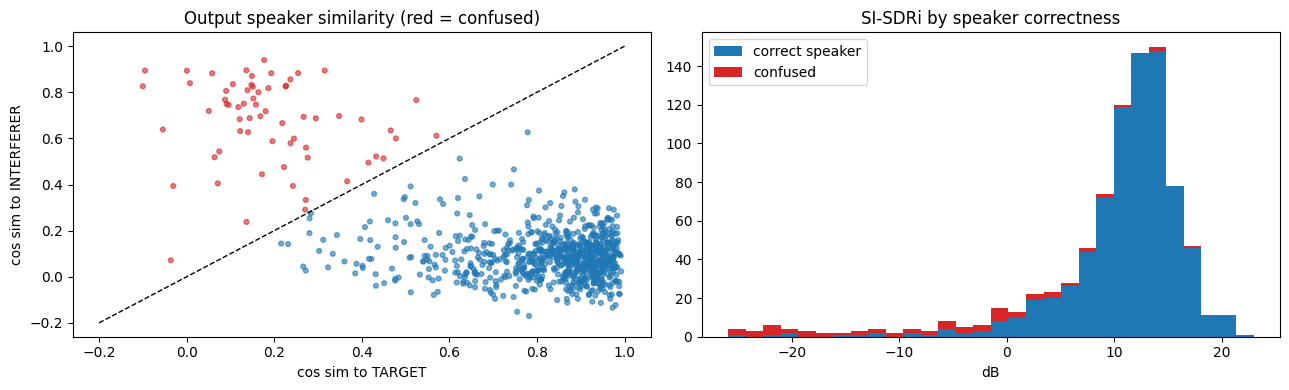

In [ ]:
import soundfile as sf, torch.nn.functional as F
from speechbrain.inference.speaker import EncoderClassifier

if "ecapa" not in globals():
    ecapa = EncoderClassifier.from_hparams(source="speechbrain/spkrec-ecapa-voxceleb",
                                           savedir="/content/ecapa", run_opts={"device": str(device)})

@torch.no_grad()
def embed(x):
    x = torch.as_tensor(x, dtype=torch.float32).reshape(1, -1).to(device)
    return F.normalize(ecapa.encode_batch(x).reshape(1, -1), dim=-1)

def load_interferer(row, max_s=5):
    # assumes int_start = sample offset into the interferer file (speaker identity is robust to exact offsets)
    path = f"{DATA}/{row.int_path}"
    n = int(max_s * SR)
    start = int(row.int_start) if not np.isnan(row.int_start) else 0
    x, sr = sf.read(path, start=start, frames=n, dtype="float32")
    if len(x) < SR:                                  # too short -> take from the beginning
        x, sr = sf.read(path, frames=n, dtype="float32")
    return x

rows = []
for i in tqdm(range(len(test_ds))):
    mix, tgt, est = cache[i]
    r = man_test.iloc[i]
    if not isinstance(r.int_path, str):              # no interferer in this scenario
        continue
    e_est, e_tgt, e_mix = embed(est), embed(tgt), embed(mix)
    e_int = embed(load_interferer(r))
    rows.append(dict(idx=i,
        sim_est_tgt=(e_est @ e_tgt.T).item(), sim_est_int=(e_est @ e_int.T).item(),
        sim_mix_tgt=(e_mix @ e_tgt.T).item()))
sp = pd.DataFrame(rows)
sp["confused"] = sp.sim_est_int > sp.sim_est_tgt
sp = sp.merge(df[["idx", "sisdri"]], on="idx")

print(f"Speaker confusion rate: {sp.confused.mean()*100:.2f}%  ({sp.confused.sum()}/{len(sp)})")
print(f"Mean speaker similarity  mixture->target: {sp.sim_mix_tgt.mean():.3f} | output->target: {sp.sim_est_tgt.mean():.3f}")
print(f"Mean SI-SDRi when correct: {sp[~sp.confused].sisdri.mean():.2f} dB | when confused: {sp[sp.confused].sisdri.mean():.2f} dB")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(sp.sim_est_tgt, sp.sim_est_int, c=sp.confused.map({True: "tab:red", False: "tab:blue"}), s=12, alpha=.6)
ax[0].plot([-.2, 1], [-.2, 1], "k--", lw=1)
ax[0].set(title="Output speaker similarity (red = confused)", xlabel="cos sim to TARGET", ylabel="cos sim to INTERFERER")
ax[1].hist([sp[~sp.confused].sisdri, sp[sp.confused].sisdri], bins=30, stacked=True,
           color=["tab:blue", "tab:red"], label=["correct speaker", "confused"])
ax[1].set(title="SI-SDRi by speaker correctness", xlabel="dB"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{PROJ}/speaker_confusion.png", dpi=150); plt.show()
sp.to_csv(f"{PROJ}/speaker_confusion.csv", index=False)

config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/1.93k [00:00<?, ?B/s]

... (7 outputs left out)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

  0%|          | 0/300 [00:00<?, ?it/s]

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


WER  mixture: 38.3%  ->  extracted: 18.1%   (reference = Whisper on clean target)
Relative WER reduction: 52.9%


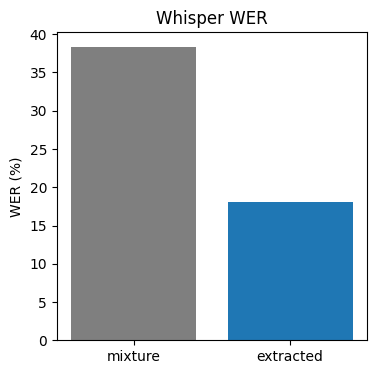

In [ ]:
!pip -q install jiwer transformers accelerate
import re, jiwer
from transformers import pipeline

asr = pipeline("automatic-speech-recognition", model="openai/whisper-small.en",
               device=0 if device.type == "cuda" else -1, torch_dtype=torch.float16 if device.type == "cuda" else torch.float32)

def norm(s): return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9' ]", " ", s.lower())).strip()
def transcribe(x): return norm(asr({"raw": x.astype(np.float32), "sampling_rate": SR})["text"])

N_WER = 300
ids = np.random.default_rng(0).choice(len(test_ds), min(N_WER, len(test_ds)), replace=False)
ref, hyp_mix, hyp_est = [], [], []
for i in tqdm(ids):
    mix, tgt, est = cache[int(i)]
    ref.append(transcribe(tgt)); hyp_mix.append(transcribe(mix)); hyp_est.append(transcribe(est))

keep = [k for k, r in enumerate(ref) if r]            # drop empty references
ref = [ref[k] for k in keep]; hyp_mix = [hyp_mix[k] for k in keep]; hyp_est = [hyp_est[k] for k in keep]
wer_mix, wer_est = jiwer.wer(ref, hyp_mix), jiwer.wer(ref, hyp_est)
print(f"WER  mixture: {wer_mix*100:.1f}%  ->  extracted: {wer_est*100:.1f}%   (reference = Whisper on clean target)")
print(f"Relative WER reduction: {(wer_mix - wer_est)/wer_mix*100:.1f}%")

plt.figure(figsize=(4, 4)); plt.bar(["mixture", "extracted"], [wer_mix*100, wer_est*100], color=["tab:gray", "tab:blue"])
plt.ylabel("WER (%)"); plt.title("Whisper WER"); plt.savefig(f"{PROJ}/wer.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
import time
from torch.utils.flop_counter import FlopCounterMode

mix, tgt, emb, *_ = test_ds[0]
m = torch.as_tensor(mix).reshape(1, -1).to(device)
e = torch.as_tensor(emb); e = e.reshape(1, -1) if e.ndim < 2 else e.reshape(1, -1)
e = e.to(device)
dur = m.shape[1] / SR

params = sum(p.numel() for p in model.parameters())
with torch.no_grad(), FlopCounterMode(display=False) as fc:
    model(m, e)
macs = fc.get_total_flops() / 2

def bench(autocast, n=20):
    for _ in range(3):                                  # warmup
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=autocast and device.type == "cuda"):
            model(m, e)
    if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(n):
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=autocast and device.type == "cuda"):
            model(m, e)
    if device.type == "cuda": torch.cuda.synchronize()
    t = (time.time() - t0) / n
    mem = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")
    return t, mem

for name, ac in [("fp32", False), ("fp16 autocast", True)]:
    t, mem = bench(ac)
    print(f"{name:14s} | {t*1000:.1f} ms for {dur:.1f}s audio | RTF {t/dur:.4f} | peak GPU mem {mem:.0f} MiB")
print(f"Parameters: {params/1e6:.2f} M | MACs: {macs/1e9:.2f} G per {dur:.1f}s clip ({macs/1e9/dur:.2f} GMACs/s of audio)")
print("GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu")

fp32           | 164.9 ms for 6.0s audio | RTF 0.0275 | peak GPU mem 1057 MiB
fp16 autocast  | 181.1 ms for 6.0s audio | RTF 0.0302 | peak GPU mem 870 MiB
Parameters: 16.83 M | MACs: 23.87 G per 6.0s clip (3.98 GMACs/s of audio)
GPU: NVIDIA L4


In [ ]:
def boot_ci(x, n=5000, seed=0):
    x = np.asarray(x.dropna()); rng = np.random.default_rng(seed)
    means = [rng.choice(x, len(x), replace=True).mean() for _ in range(n)]
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

tbl = []
for col in ["sisdr_in", "sisdr_out", "sisdri", "stoi_in", "stoi_out", "pesq_out"]:
    mu, lo, hi = boot_ci(df[col]); tbl.append(dict(metric=col, mean=mu, ci_low=lo, ci_high=hi))
tbl = pd.DataFrame(tbl).round(3); display(tbl)
tbl.to_csv(f"{PROJ}/metrics_ci.csv", index=False)

,metric,mean,ci_low,ci_high
0,sisdr_in,5.947,4.620,7.327
1,sisdr_out,12.715,12.085,13.341
2,sisdri,6.767,5.733,7.762
3,stoi_in,0.785,0.777,0.792
4,stoi_out,0.879,0.870,0.887
5,pesq_out,2.329,2.276,2.383


                n  sisdr_in  sisdr_out  sisdri  stoi_in  stoi_out  pesq
scenario                                                               
clean          65    104.86      41.64  -63.22     1.00      1.00  4.62
noise         290      4.22      17.73   13.51     0.90      0.95  2.89
speech        294      1.15      10.81    9.65     0.76      0.88  2.29
speech_noise  551     -2.25       7.68    9.93     0.71      0.83  1.78


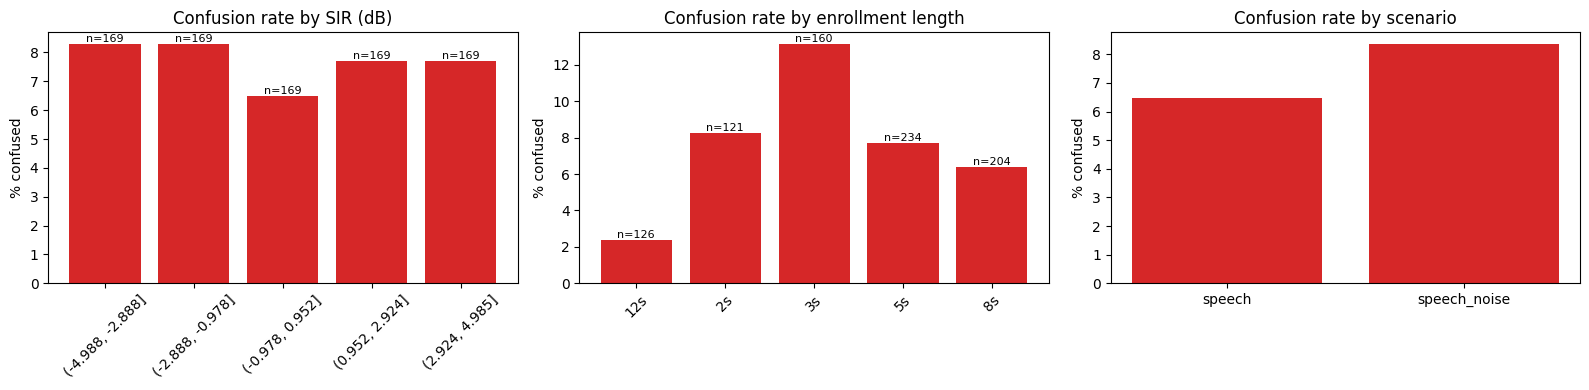

Overall SI-SDRi now: 6.77 dB | if confusions behaved like correct samples: 7.72 dB


In [ ]:
d = df.merge(man_test.reset_index().rename(columns={"index": "idx"}), on="idx")
d = d.merge(sp[["idx", "confused", "sim_est_tgt", "sim_est_int"]], on="idx", how="left")

# 1) per-scenario results (checks the ~0 dB hypothesis above)
print(d.groupby("scenario").agg(n=("idx", "size"), sisdr_in=("sisdr_in", "mean"),
      sisdr_out=("sisdr_out", "mean"), sisdri=("sisdri", "mean"),
      stoi_in=("stoi_in", "mean"), stoi_out=("stoi_out", "mean"),
      pesq=("pesq_out", "mean")).round(2))

# 2) what drives speaker confusion? (interferer scenarios only)
x = d.dropna(subset=["confused"]).copy()
x["confused"] = x["confused"].astype(float)
x["sir_bin"] = pd.qcut(x.sir, 5, duplicates="drop")
x["enroll_bin"] = x.enroll_dur.astype(int).astype(str) + "s"

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, title in [(ax[0], "sir_bin", "Confusion rate by SIR (dB)"),
                      (ax[1], "enroll_bin", "Confusion rate by enrollment length")]:
    g = x.groupby(col, observed=True).confused.agg(["mean", "size"])
    a.bar([str(i) for i in g.index], g["mean"] * 100, color="tab:red")
    for k, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(k, m * 100, f"n={n}", ha="center", va="bottom", fontsize=8)
    a.set(title=title, ylabel="% confused"); a.tick_params(axis="x", rotation=45)
x2 = x.groupby("scenario").confused.mean() * 100
ax[2].bar(x2.index, x2.values, color="tab:red"); ax[2].set(title="Confusion rate by scenario", ylabel="% confused")
plt.tight_layout(); plt.savefig(f"{PROJ}/confusion_drivers.png", dpi=150); plt.show()

# 3) how much would fixing confusion help overall?
fixed = d.copy()
fixed.loc[fixed.confused == 1, "sisdri"] = d[d.confused == 0].sisdri.mean()
print(f"Overall SI-SDRi now: {d.sisdri.mean():.2f} dB | if confusions behaved like correct samples: {fixed.sisdri.mean():.2f} dB")

In [ ]:
# --- 1) corrected headline table (exclude 'clean'), with bootstrap CIs ---
d = df.merge(man_test.reset_index().rename(columns={"index": "idx"}), on="idx")
dn = d[d.scenario != "clean"]
tbl = []
for col in ["sisdr_in", "sisdr_out", "sisdri", "stoi_in", "stoi_out", "pesq_out"]:
    mu, lo, hi = boot_ci(dn[col]); tbl.append(dict(metric=col, mean=mu, ci_low=lo, ci_high=hi))
tbl = pd.DataFrame(tbl).round(3); display(tbl); tbl.to_csv(f"{PROJ}/metrics_ci_noclean.csv", index=False)

# --- 2) per-scenario table with CIs on SI-SDRi ---
rows = []
for sc, g in d.groupby("scenario"):
    mu, lo, hi = boot_ci(g.sisdri)
    rows.append(dict(scenario=sc, n=len(g), sisdr_in=g.sisdr_in.mean(), sisdr_out=g.sisdr_out.mean(),
                     sisdri=mu, sisdri_lo=lo, sisdri_hi=hi, stoi_out=g.stoi_out.mean(), pesq=g.pesq_out.mean()))
sc_tbl = pd.DataFrame(rows).round(2); display(sc_tbl); sc_tbl.to_csv(f"{PROJ}/metrics_by_scenario.csv", index=False)

# --- 3) WER per scenario (reuses ids/keep/ref/hyp lists from the Whisper cell) ---
kept_ids = np.asarray(ids)[keep]
scen = man_test.scenario.values[kept_ids]
res = []
for sc in np.unique(scen):
    m = scen == sc
    r = [ref[k] for k in np.where(m)[0]]
    res.append(dict(scenario=sc, n=int(m.sum()),
                    wer_mix=jiwer.wer(r, [hyp_mix[k] for k in np.where(m)[0]]) * 100,
                    wer_est=jiwer.wer(r, [hyp_est[k] for k in np.where(m)[0]]) * 100))
w = pd.DataFrame(res).round(1); display(w)
nc = scen != "clean"
r = [ref[k] for k in np.where(nc)[0]]
print(f"WER excluding clean: mixture {jiwer.wer(r, [hyp_mix[k] for k in np.where(nc)[0]])*100:.1f}% -> "
      f"extracted {jiwer.wer(r, [hyp_est[k] for k in np.where(nc)[0]])*100:.1f}%")

,metric,mean,ci_low,ci_high
0,sisdr_in,0.283,-0.000,0.560
1,sisdr_out,11.058,10.556,11.561
2,sisdri,10.775,10.337,11.206
3,stoi_in,0.772,0.765,0.780
4,stoi_out,0.872,0.863,0.880
5,pesq_out,2.197,2.152,2.243


,scenario,n,sisdr_in,sisdr_out,sisdri,sisdri_lo,sisdri_hi,stoi_out,pesq
0,clean,65,104.86,41.64,-63.22,-64.93,-61.67,1.00,4.62
1,noise,290,4.22,17.73,13.51,12.79,14.23,0.95,2.89
2,speech,294,1.15,10.81,9.65,8.70,10.56,0.88,2.29
3,speech_noise,551,-2.25,7.68,9.93,9.30,10.52,0.83,1.78


,scenario,n,wer_mix,wer_est
0,clean,15,0.0,0.0
1,noise,77,7.0,5.8
2,speech,77,40.4,10.5
3,speech_noise,131,60.0,31.9


WER excluding clean: mixture 40.2% -> extracted 18.9%


In [ ]:
import json
summary = {
    "wer_mixture_all": float(wer_mix), "wer_extracted_all": float(wer_est),
    "wer_by_scenario": w.to_dict(orient="records"),
    "speaker_confusion_rate": float(sp.confused.mean()),
    "speaker_sim_mix_to_target": float(sp.sim_mix_tgt.mean()),
    "speaker_sim_out_to_target": float(sp.sim_est_tgt.mean()),
    "efficiency": {"params_M": params / 1e6, "GMACs_per_clip": macs / 1e9, "clip_seconds": dur,
                   "gpu": torch.cuda.get_device_name(0)},
    "checkpoint_used": CKPT,
}
json.dump(summary, open(f"{PROJ}/results_summary.json", "w"), indent=2)

# also keep the WER transcripts, in case you want to inspect failures later
pd.DataFrame({"idx": np.asarray(ids)[keep], "ref": ref, "hyp_mix": hyp_mix, "hyp_est": hyp_est}) \
  .to_csv(f"{PROJ}/wer_transcripts.csv", index=False)
print("saved")

saved
